# Klasifikasi Multikelas: Estimation of Obesity Levels

Dataset ini berisi data estimasi tingkat obesitas individu di Meksiko, Peru, dan Kolombia berdasarkan kebiasaan makan dan kondisi fisik harian. Data bersumber dari UCI Machine Learning Repository.

- Nama dataset: Estimation of Obesity Levels Based On Eating Habits and Physical Condition
- Sumber data: UCI Machine Learning Repository (ID: 544)
- Link dataset: https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition
- Dimensi data: 2.111 baris dan 17 kolom (16 fitur perilaku/fisik dan 1 kolom target)
- Variabel target: Kolom `NObeyesdad` dengan 7 tingkatan kategori berat badan

In [1]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

obesity = fetch_ucirepo(id=544)
X = obesity.data.features
y = obesity.data.targets
df = pd.concat([X, y], axis=1)

print("Shape data:", df.shape)
display(df.head())
print("\nTipe data:")
print(df.dtypes)

Shape data: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II



Tipe data:
Gender                                str
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight        str
FAVC                                  str
FCVC                              float64
NCP                               float64
CAEC                                  str
SMOKE                                 str
CH2O                              float64
SCC                                   str
FAF                               float64
TUE                               float64
CALC                                  str
MTRANS                                str
NObeyesdad                            str
dtype: object


Jumlah kelas: 7 => multikelas: True

Distribusi kelas:
NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64


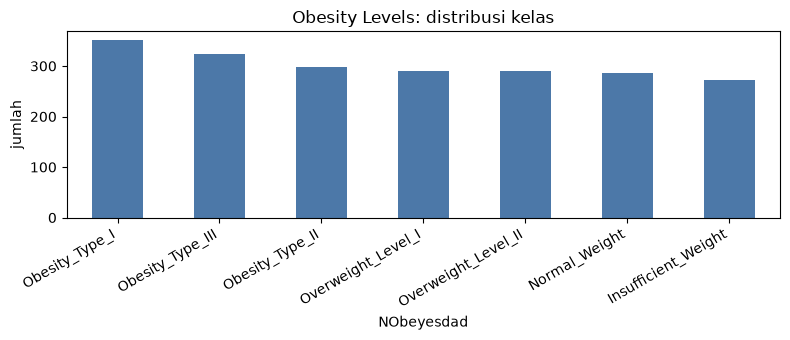

In [2]:
import matplotlib.pyplot as plt

def plot_dist(y, title, rot=0):
    ax = pd.Series(y).value_counts().plot(kind="bar", figsize=(8, 3.5), color="#4C78A8")
    ax.set_title(title)
    ax.set_ylabel("jumlah")
    plt.xticks(rotation=rot, ha="right" if rot > 0 else "center")
    plt.tight_layout()
    plt.show()

target_col = "NObeyesdad"

print("Jumlah kelas:", df[target_col].nunique(), "=> multikelas:", df[target_col].nunique() > 2)
print("\nDistribusi kelas:")
print(df[target_col].value_counts())
plot_dist(df[target_col], "Obesity Levels: distribusi kelas", rot=30)

In [3]:
assert df[target_col].nunique() == 7, f"Nilai unik harus berjumlah 7, didapat: {df[target_col].nunique()}"
assert df[target_col].nunique() > 2, "Harus lebih dari 2 kelas untuk multikelas"
assert df[target_col].isnull().sum() == 0, "Target mengandung nilai null"
assert df.shape == (2111, 17), f"Bentuk dataframe tidak sesuai: {df.shape}"

print("Semua verifikasi lolos.")

Semua verifikasi lolos.


## Kesimpulan

Dataset Obesity Levels termasuk dalam klasifikasi multikelas karena kolom target `NObeyesdad` memiliki 7 kategori diskret:
- Obesity_Type_I (351 sampel)
- Obesity_Type_III (324 sampel)
- Obesity_Type_II (297 sampel)
- Overweight_Level_I (290 sampel)
- Overweight_Level_II (290 sampel)
- Normal_Weight (287 sampel)
- Insufficient_Weight (272 sampel)

Setiap individu hanya dikelompokkan ke dalam satu tingkatan berat badan tanpa ada label ganda.